<a href="https://colab.research.google.com/github/Tushar-3512/Data-Science-Practical-/blob/main/Practical3_pynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/student_rating_dataset.csv')
df.head()

,prof_id,department,gender,minority,native_english,age,tenure,beauty_score,num_students,eval_score
0,1,Electrical,Male,No,Yes,48,Yes,1.14,244,3.88
1,2,Physics,Female,Yes,Yes,38,No,-0.46,131,3.80
2,3,Physics,Male,Yes,Yes,38,No,-0.67,173,3.99
3,4,Mechanical,Female,No,Yes,38,No,0.38,114,4.57
4,5,Civil,Male,No,Yes,48,Yes,-0.44,206,4.02


1. Calculate the percentage of visible minorities are tenure professors,Will you say that tenure status differed if teacher was a visible minority?

In [ ]:
minority_df = df[df['minority'] == 'Yes']
pct_tenured_minority = (minority_df['tenure'] == 'Yes').mean() * 100
print(f"% of minority professors who are tenured: {pct_tenured_minority:.2f}%")

tenure_by_minority = pd.crosstab(df['minority'], df['tenure'], normalize='index') * 100
print(tenure_by_minority)

print("59.18% of visible minority professors are tenured.")
print("Comparing groups, 59.18% of minority professors are tenured vs 57.62% of non-minority professors — a difference of only ~1.56 percentage points.")
print("This is a small gap, so tenure status does not appear to differ meaningfully based on whether a professor is a visible minority.")

% of minority professors who are tenured: 59.18%
tenure           No        Yes
minority                      
No        42.384106  57.615894
Yes       40.816327  59.183673
59.18% of visible minority professors are tenured.
Comparing groups, 59.18% of minority professors are tenured vs 57.62% of non-minority professors — a difference of only ~1.56 percentage points.
This is a small gap, so tenure status does not appear to differ meaningfully based on whether a professor is a visible minority.


2. Does average age differ by tenure? Produce the means and standard deviations for both tenured and untenured professors

In [ ]:
age_stats = df.groupby('tenure')['age'].agg(['mean', 'std'])
print(age_stats)
print("The average age of untenured professors is 37.30 years (SD = 6.86), while the average age of tenured professors is 51.63 years (SD = 8.25)")
print("This is a difference of about 14.3 years, which is a substantial gap.")
print("So yes, average age clearly differs by tenure status — tenured professors tend to be considerably older than untenured professors.")

             mean       std
tenure                     
No      37.297619  6.864927
Yes     51.629310  8.245716
The average age of untenured professors is 37.30 years (SD = 6.86), while the average age of tenured professors is 51.63 years (SD = 8.25)
This is a difference of about 14.3 years, which is a substantial gap.
So yes, average age clearly differs by tenure status — tenured professors tend to be considerably older than untenured professors.


3. Which graph works better and plot that graph for the age variable?

The histogram works best for the age variable, since age is a continuous numerical
variable, and a histogram is the standard chart for displaying the distribution (shape, spread, and skew) of continuous data by grouping values into bins.


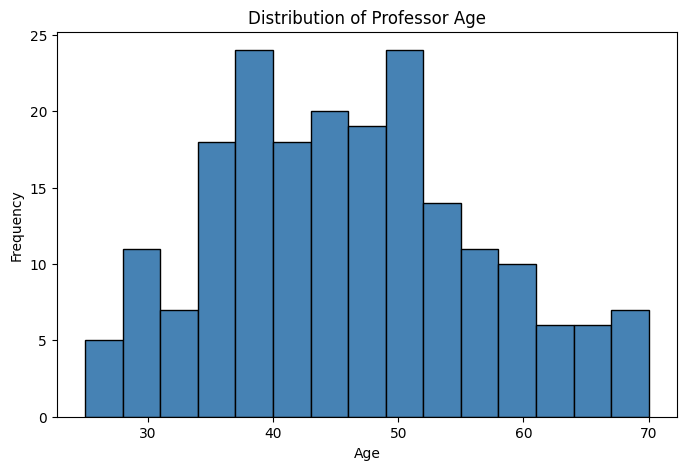

Observation from the graph: The age distribution is roughly spread between 25 and 70,
with a noticeable cluster of professors in the 35–40 and 55–60 age ranges, and relatively fewer professors above 60.


In [ ]:
print("The histogram works best for the age variable, since age is a continuous numerical")
print("variable, and a histogram is the standard chart for displaying the distribution (shape, spread, and skew) of continuous data by grouping values into bins.")
plt.figure(figsize=(8,5))
plt.hist(df['age'], bins=15, color='steelblue', edgecolor='black')
plt.title('Distribution of Professor Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()
print("Observation from the graph: The age distribution is roughly spread between 25 and 70,")
print("with a noticeable cluster of professors in the 35–40 and 55–60 age ranges, and relatively fewer professors above 60.")

4. Define the difference between pyplot.bar and pyplot.barh. Also plot the graph for gender variable.

In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    'Feature': ['Full name', 'Bar direction', 'x-axis shows', 'y-axis shows', 'Best used when'],
    'plt.bar()': ['Vertical bar chart', 'Bars go up', 'Categories', 'Values/Counts', 'Few categories, short labels'],
    'plt.barh()': ['Horizontal bar chart', 'Bars go sideways', 'Values/Counts', 'Categories', 'Many categories, long labels']
})

comparison

,Feature,plt.bar(),plt.barh()
0,Full name,Vertical bar chart,Horizontal bar chart
1,Bar direction,Bars go up,Bars go sideways
2,x-axis shows,Categories,Values/Counts
3,y-axis shows,Values/Counts,Categories
4,Best used when,"Few categories, short labels","Many categories, long labels"


gender
Male      103
Female     97
Name: count, dtype: int64


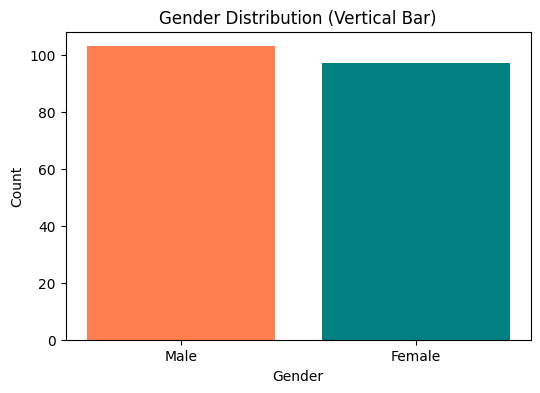

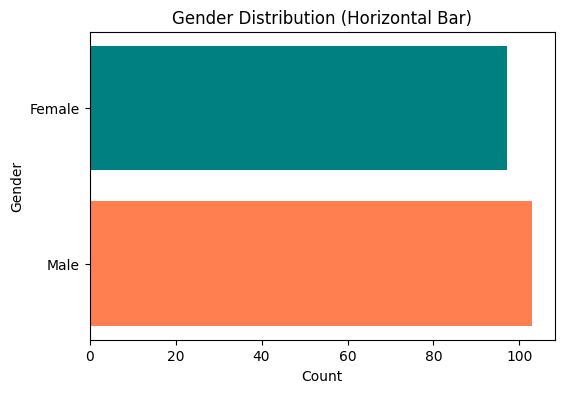

In [ ]:
gender_counts = df['gender'].value_counts()
print(gender_counts)

# Vertical bar chart
plt.figure(figsize=(6,4))
plt.bar(gender_counts.index, gender_counts.values, color=['coral','teal'])
plt.title('Gender Distribution (Vertical Bar)')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

# Horizontal bar chart
plt.figure(figsize=(6,4))
plt.barh(gender_counts.index, gender_counts.values, color=['coral','teal'])
plt.title('Gender Distribution (Horizontal Bar)')
plt.xlabel('Count')
plt.ylabel('Gender')
plt.show()

5. What is the Median evaluation score for tenured Professors?

In [ ]:
median_eval_tenured = df[df['tenure'] == 'Yes']['eval_score'].median()
print(f"Median evaluation score for tenured professors: {median_eval_tenured:.2f}")
print("The median evaluation score for tenured professors is 3.94 (on a 1–5 scale).")
print("This means half of tenured professors received an evaluation score of 3.94 or higher, and half received lower.")

Median evaluation score for tenured professors: 3.94
The median evaluation score for tenured professors is 3.94 (on a 1–5 scale).
This means half of tenured professors received an evaluation score of 3.94 or higher, and half received lower.
